# NASA battery data — what's actually in the files

Read-only reconnaissance before any model is written. Nothing here trains anything.

All logic lives in `src/explore_nasa.py` — this notebook only calls it, so the two
cannot drift out of sync.

In [1]:
import os, sys
from pathlib import Path

# Jupyter starts wherever this file lives (originally notebooks/, now
# documents/), but the scripts use paths relative to the project root
# (data/raw, data/processed, src/). Detect the root by presence of src/
# rather than by folder name, so this keeps working regardless of which
# subfolder the notebook is opened from.
if not (Path.cwd() / "src").is_dir():
    os.chdir("..")
sys.path.insert(0, "src")

from fetch_nasa import main as fetch_dataset
from explore_nasa import find_mat_files, probe, extract_discharges, summarise

print("working dir:", Path.cwd())

# Fetch and unpack the dataset if it isn't here yet: ~210 MB, a few minutes on the
# first run, instant afterwards. Nothing in this notebook needs doing by hand --
# just Run All.
if list(Path("data/raw").rglob("*.mat")):
    print("dataset already present")
else:
    fetch_dataset()

working dir: C:\Users\wiece\OneDrive\Desktop\FaradayX\GrunussWorkspace\PaaS4Bat_PINN_CaseStudy_YourName
dataset already present


## 1. Which files did we get?

The download ships 38 `.mat` files across six aging campaigns at several ambient
temperatures. We use only the 24 °C room-temperature group — B0005, B0006, B0007,
B0018 — because one rate constant cannot be fitted across incompatible thermal
conditions (decision D-001).

Pass `find_mat_files(cells=None)` to see all of them.

In [2]:
files = find_mat_files()
for f in files:
    print(f"{f.stat().st_size / 1e6:7.1f} MB  {f}")

    

   16.0 MB  data\raw\nasa_battery\5. Battery Data Set\1. BatteryAgingARC-FY08Q4\B0005.mat
   16.0 MB  data\raw\nasa_battery\5. Battery Data Set\1. BatteryAgingARC-FY08Q4\B0006.mat
   16.0 MB  data\raw\nasa_battery\5. Battery Data Set\1. BatteryAgingARC-FY08Q4\B0007.mat
    8.5 MB  data\raw\nasa_battery\5. Battery Data Set\1. BatteryAgingARC-FY08Q4\B0018.mat


## 2. Schema probe

Walks the nested MATLAB structs and reports the record types, their field names,
and the array shapes of one discharge record. Nothing is assumed to exist — if the
layout differs from expectation, the output says so rather than raising a KeyError
later inside a training loop.

In [3]:
probe(files[0])


B0005.mat   top-level keys: ['B0005']
  'B0005'.cycle -> 616 records
  record types: {'charge': 170, 'discharge': 168, 'impedance': 278}
    charge       data fields: ['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_charge', 'Voltage_charge', 'Time']
    discharge    data fields: ['Voltage_measured', 'Current_measured', 'Temperature_measured', 'Current_load', 'Voltage_load', 'Time', 'Capacity']
    impedance    data fields: ['Sense_current', 'Battery_current', 'Current_ratio', 'Battery_impedance', 'Rectified_Impedance', 'Re', 'Rct']
    first discharge  ambient=24 C  start=2008-04-02 15:25:41.593000
      Voltage_measured       shape=(197,) dtype=float64 first=4.191491807505295
      Current_measured       shape=(197,) dtype=float64 first=-0.004901589207462691
      Temperature_measured   shape=(197,) dtype=float64 first=24.330033885570543
      Current_load           shape=(197,) dtype=float64 first=-0.0006
      Voltage_load           shape=(197,) dtype=floa

## 3. The capacity series

One row per discharge cycle: capacity, start timestamp → elapsed hours, mean cell
temperature, rest gap, SOH.

Three numbers to read here:

- **regeneration steps** — cycles that *gained* capacity. A strictly monotone model
  cannot express these; that is why the hard-constraint rung is expected to fail.
- **longest rest** — confirms that cycle index and wall-clock time are not
  proportional, so the physics must run on elapsed hours (decision D-008).
- **cell temp range** — how much the Arrhenius term has to work with (D-010).

In [4]:
frames = {}
for path in files:
    df = extract_discharges(path)
    frames[path.stem] = df
    summarise(path.stem, df)
    


  B0005
    discharge cycles     168
    capacity   1.8565 -> 1.3251 Ah   (SOH 71.4%)
    elapsed              1325.3 h (55.2 days)
    cell temp     mean 32.8 C   range 31.3-34.3 C
    longest rest         310.4 h
    REGENERATION steps   36 / 167 (22% of cycles gained capacity)



  B0006
    discharge cycles     168
    capacity   2.0353 -> 1.1857 Ah   (SOH 58.3%)
    elapsed              1325.3 h (55.2 days)
    cell temp     mean 32.8 C   range 30.8-34.5 C
    longest rest         310.4 h
    REGENERATION steps   27 / 167 (16% of cycles gained capacity)



  B0007
    discharge cycles     168
    capacity   1.8911 -> 1.4325 Ah   (SOH 75.7%)
    elapsed              1325.3 h (55.2 days)
    cell temp     mean 32.4 C   range 30.9-33.9 C
    longest rest         310.4 h
    REGENERATION steps   47 / 167 (28% of cycles gained capacity)

  B0018
    discharge cycles     132
    capacity   1.8550 -> 1.3411 Ah   (SOH 72.3%)
    elapsed              1049.4 h (43.7 days)
    cell temp     mean 31.1 C   range 30.1-32.0 C
    longest rest         244.7 h
    REGENERATION steps   21 / 131 (16% of cycles gained capacity)


In [5]:
frames[files[0].stem].head(12)

,record_index,start,capacity_ah,ambient_c,temp_mean_c,temp_max_c,cycle,elapsed_h,soh,delta_capacity,rest_h
0,1,2008-04-02 15:25:41.593,1.856487,24.0,32.572328,38.982181,1,0.000000,1.000000,NaN,NaN
1,3,2008-04-02 19:43:48.406,1.846327,24.0,32.725235,39.033398,2,4.301893,0.994527,-0.010160,4.301893
2,5,2008-04-03 00:01:06.687,1.835349,24.0,32.642862,38.818797,3,8.590304,0.988614,-0.010978,4.288411
3,7,2008-04-03 04:16:37.375,1.835263,24.0,32.514876,38.762305,4,12.848828,0.988567,-0.000087,4.258524
4,9,2008-04-03 08:33:25.703,1.834646,24.0,32.382349,38.665393,5,17.128919,0.988235,-0.000617,4.280091
5,11,2008-04-03 12:55:10.687,1.835662,24.0,32.434182,38.751695,6,21.491415,0.988782,0.001016,4.362496
6,13,2008-04-03 17:17:16.015,1.835146,24.0,32.480416,38.820701,7,25.859562,0.988504,-0.000516,4.368147
7,15,2008-04-03 21:28:14.718,1.825757,24.0,32.410462,38.517130,8,30.042535,0.983447,-0.009389,4.182973
8,17,2008-04-04 01:38:15.218,1.824774,24.0,32.346141,38.526268,9,34.209340,0.982917,-0.000983,4.166806
9,19,2008-04-04 05:48:08.609,1.824613,24.0,32.276798,38.526981,10,38.374171,0.982831,-0.000161,4.164831


## 4. Overview plots

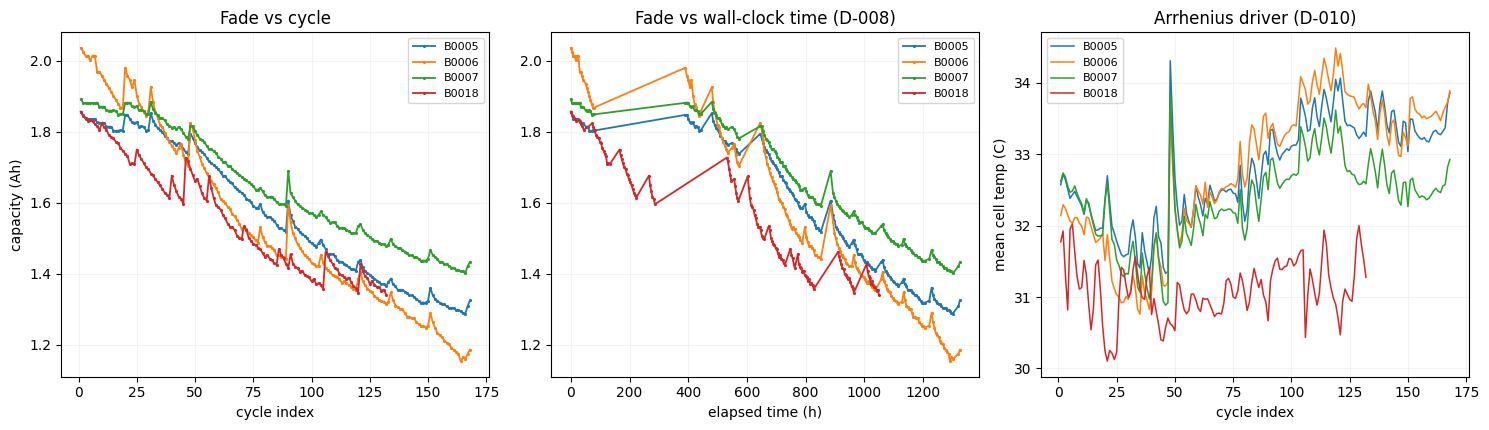

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for name, df in frames.items():
    if df.empty:
        continue
    axes[0].plot(df["cycle"], df["capacity_ah"], lw=1.3, marker=".", ms=2.5, label=name)
    axes[1].plot(df["elapsed_h"], df["capacity_ah"], lw=1.3, marker=".", ms=2.5, label=name)
    axes[2].plot(df["cycle"], df["temp_mean_c"], lw=1.1, label=name)

axes[0].set(xlabel="cycle index", ylabel="capacity (Ah)", title="Fade vs cycle")
axes[1].set(xlabel="elapsed time (h)", title="Fade vs wall-clock time (D-008)")
axes[2].set(xlabel="cycle index", ylabel="mean cell temp (C)", title="Arrhenius driver (D-010)")
for ax in axes:
    ax.grid(alpha=0.15)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. Regeneration, close up

Capacity recovered after a rest, plotted against the length of that rest. If there is
a relationship here, the reversible channel in the final model has something real to
latch onto.

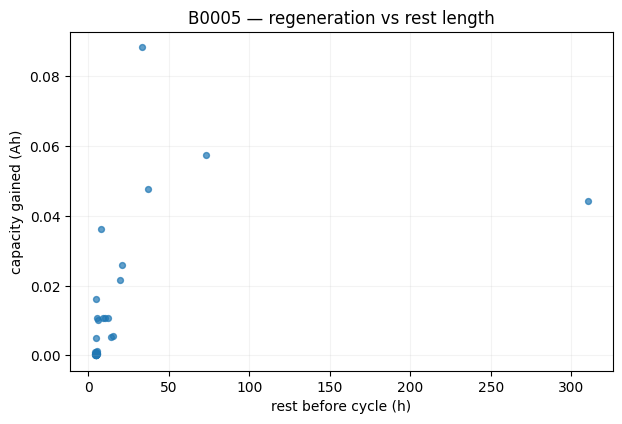

36 of 167 cycles gained capacity
largest single gain: 0.0883 Ah


In [7]:
df = frames[files[0].stem]
gain = df[df["delta_capacity"] > 0]

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.scatter(gain["rest_h"], gain["delta_capacity"], s=18, alpha=0.7)
ax.set(xlabel="rest before cycle (h)", ylabel="capacity gained (Ah)",
       title=f"{files[0].stem} — regeneration vs rest length")
ax.grid(alpha=0.15)
plt.show()

print(f"{len(gain)} of {len(df) - 1} cycles gained capacity")
print(f"largest single gain: {gain['delta_capacity'].max():.4f} Ah")

## 6. Normalizing units — making sure Capacity is in Ah

NASA's docs say `Capacity` is in Ah, but nothing enforced that until now. A
mislabeled mAh source would silently read as a cell that lost 99.9% of its
capacity in one cycle, and nothing downstream would flag it.


In [8]:
import pandas as pd

all_caps = pd.concat([df["capacity_ah"] for df in frames.values()])

# in express discharges step 3 we made sure Capacity is between 0.5-3.0 Ah 
print("capacity_ah range across all cells and cycles:")
print(f"  min = {all_caps.min():.4f} Ah")
print(f"  max = {all_caps.max():.4f} Ah")
print(f"  assertion bound in extract_discharges(): 0.5 < capacity_ah < 3.0 Ah")
print("  every row above already passed that check -- extract_discharges() would")
print("  have raised AssertionError on the first violating row otherwise.")

capacity_ah range across all cells and cycles:
  min = 1.1538 Ah
  max = 2.0353 Ah
  assertion bound in extract_discharges(): 0.5 < capacity_ah < 3.0 Ah
  every row above already passed that check -- extract_discharges() would
  have raised AssertionError on the first violating row otherwise.


## 7. Normalizing units — checking for outlier/NaN in temperature

In [9]:
import pandas as pd
import numpy as np


all_temp_mean_c = pd.concat([df["temp_mean_c"] for df in frames.values()])
all_temp_max_c = pd.concat([df["temp_max_c"] for df in frames.values()])

# in express discharges step 3 we made sure Capacity is between 0.5-3.0 Ah 
print("range of mean temperature")
print(f"  min = {all_temp_mean_c.min():.4f} C")
print(f"  max = {all_temp_mean_c.max():.4f} C")
print("range of max temperature")
print(f"  min = {all_temp_max_c.min():.4f} C")
print(f"  max = {all_temp_max_c.max():.4f} C")


#  Data Type check
assert pd.api.types.is_numeric_dtype(all_temp_mean_c), "temp_mean_c is not numeric!"

# 2. NaN and Inf checks
nan_count = all_temp_mean_c.isna().sum()
inf_count = np.isinf(all_temp_mean_c).sum()

print(f"NaN count: {nan_count}")
print(f"Inf count: {inf_count}")

range of mean temperature
  min = 30.1027 C
  max = 34.4905 C
range of max temperature
  min = 36.3721 C
  max = 42.3325 C
NaN count: 0
Inf count: 0


## 8. Normalizing units — checking if Max > Mean temperature

In [10]:
invalid_rows = [
    stem for stem, df in frames.items() 
    if (df["temp_max_c"] < df["temp_mean_c"]).any()
]
print(f"Frames with temp_max < temp_mean: {invalid_rows}")

#this is a positive signal
# Frames with temp_max < temp_mean: [] 

Frames with temp_max < temp_mean: []


## 9. Sanity check in cycle, elapsed_h, soh, delta_capacity,rest_h

In [11]:
import pandas as pd
import numpy as np

def validate_capacity_series(frames: dict[str, pd.DataFrame]):
    issues = []
    
    for name, df in frames.items():
        # 1. NaN checks
        unexpected_nans = df.iloc[1:].isna().sum().to_dict()
        if any(v > 0 for v in unexpected_nans.values()):
            issues.append(f"[{name}] Unexpected NaNs after cycle 1: {unexpected_nans}")

        # 2. Monotonicity checks
        if not df["cycle"].is_monotonic_increasing:
            issues.append(f"[{name}] Cycles are not strictly increasing.")
        if not df["elapsed_h"].is_monotonic_increasing:
            issues.append(f"[{name}] elapsed_h is not strictly increasing.")

        # 3. Value Range checks
        if (df["soh"] <= 0).any() or (df["soh"] > 1.05).any():
            issues.append(f"[{name}] SOH values out of physical bounds (0, 1.05].")
        if (df["rest_h"].dropna() < 0).any():
            issues.append(f"[{name}] Negative rest_h values found.")

            # 4. Delta Capacity Math check
            calculated_diff = df["soh"].diff()
            mismatch = ~np.isclose(df["delta_capacity"].dropna(), calculated_diff.dropna(), atol=1e-5)
            if mismatch.any():
                issues.append(f"[{name}] delta_capacity mismatches SOH.diff() at {mismatch.sum()} rows.")

    if not issues:
        print(" All sanity checks passed cleanly!")
    else:
        for issue in issues:
            print(f"❌ {issue}")

# Run the validation
validate_capacity_series(frames)

 All sanity checks passed cleanly!


There are inconsistencies in some Delta capacity so we are recalculating delta_capacity 


In [12]:
import pandas as pd
import numpy as np

cleaned_frames = {}

for stem, df in frames.items():
    df_clean = df.copy()
    
    # 1. Recompute delta_capacity directly from ground-truth capacity (in Ah)
    if "capacity" in df_clean.columns:
        df_clean["delta_capacity"] = df_clean["capacity"].diff()
    else:
        # Fallback if using SOH directly
        df_clean["delta_capacity"] = df_clean["soh"].diff()
        
    # 2. Slice out row 1 (index 0) to remove initial NaNs and reset index
    df_clean = df_clean.iloc[1:].reset_index(drop=True)
    
    cleaned_frames[stem] = df_clean

# Update your main dictionary with the clean versions
frames = cleaned_frames

## Starting With a Clean frame

In [13]:
# Create a clean dictionary of frames starting from cycle 2 (no NaNs)
clean_frames = {
    stem: df.iloc[1:].copy().reset_index(drop=True) 
    for stem, df in frames.items()
}

In [14]:
df.head(20)

# final check

,record_index,start,capacity_ah,ambient_c,temp_mean_c,temp_max_c,cycle,elapsed_h,soh,delta_capacity,rest_h
0,2,2008-07-07 15:15:28.875,1.855005,24.0,31.773285,38.101803,1,0.000000,1.000000,NaN,NaN
1,6,2008-07-07 21:53:06.125,1.843196,24.0,31.924892,38.149880,2,6.627014,0.993634,-0.011809,6.627014
2,10,2008-07-08 02:56:08.453,1.839602,24.0,31.316913,37.526691,3,11.677661,0.991697,-0.003594,5.050647
3,14,2008-07-08 07:58:55.953,1.830674,24.0,30.821191,37.062792,4,16.724188,0.986884,-0.008928,5.046528
4,17,2008-07-08 18:57:48.968,1.832700,24.0,31.953470,38.211035,5,27.705581,0.987976,0.002027,10.981393
5,19,2008-07-08 22:57:17.203,1.828529,24.0,32.023112,38.174965,6,31.696758,0.985727,-0.004171,3.991176
6,21,2008-07-09 02:56:41.281,1.821201,24.0,31.634533,37.640387,7,35.686779,0.981777,-0.007328,3.990022
7,23,2008-07-09 06:55:54.875,1.815170,24.0,31.288195,37.376029,8,39.673889,0.978526,-0.006031,3.987109
8,26,2008-07-09 11:26:41.906,1.804298,24.0,31.111225,37.289280,9,44.186953,0.972665,-0.010872,4.513064
9,29,2008-07-10 16:34:39.859,1.823100,24.0,31.131670,37.523778,10,73.319718,0.982801,0.018802,29.132765


## Export to CSV for the training step


In [15]:
from pathlib import Path

# Define path using pathlib's / operator
output_path = Path.cwd() / "data" / "processed" / "clean_data.csv"

# Optional: ensure the directory exists before saving
output_path.parent.mkdir(parents=True, exist_ok=True)

df_clean.to_csv(output_path, index=False, sep=';')
print(f" Saved: {output_path} ({len(df_clean)} rows, 0 NaNs)")

 Saved: C:\Users\wiece\OneDrive\Desktop\FaradayX\GrunussWorkspace\PaaS4Bat_PINN_CaseStudy_YourName\data\processed\clean_data.csv (131 rows, 0 NaNs)